<a href="https://colab.research.google.com/github/Okohfrank/Water-Portability-Project/blob/main/Water_Potability_Prediction_Using_Machine_Learning_Machine_Learning_Capstone_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Water Potability Prediction Using Machine Learning

### Machine Learning Capstone Project

This project uses machine learning techniques to predict whether water is potable or non-potable based on selected water-quality parameters.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import mannwhitneyu
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

# 1. Data Acquisition

## 1.1 Source
We used the **Water Potability** dataset from Github, georgefrederick's repository.

We chose it because the task is a real classification problem with a clear target (safe or not safe), the features are physical and chemical measurements we can explain, and it has realistic problems (missing values, outliers) that give us something meaningful to clean.

## 1.2 What each column means

| Column | Meaning | Unit |
|---|---|---|
| `ph` | Acidity or alkalinity of the water | scale of 0 to 14 |
| `Hardness` | Calcium and magnesium dissolved in the water | mg/L |
| `Solids` | Total dissolved solids (TDS) | ppm |
| `Chloramines` | Chloramine disinfectant level | ppm |
| `Sulfate` | Dissolved sulfate | mg/L |
| `Conductivity` | How well the water conducts electricity | μS/cm |
| `Organic_carbon` | Total organic carbon | ppm |
| `Trihalomethanes` | By-products formed when chlorine reacts with organic matter | μg/L |
| `Turbidity` | Cloudiness of the water | NTU |
| `Potability` | **Target.** 1 = potable, 0 = not potable | 0 or 1 |


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving water_potability.csv to water_potability (1).csv


In [ ]:
df = pd.read_csv('water_potability.csv')
df.head(10)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562,0


**First look at the data.** Before changing anything, we check the size of the table, the type of each column and the basic statistics. This tells us what needs cleaning.

In [ ]:
print("Shape (rows, columns):", df.shape)
print()
df.info()
display(df.describe().T.round(2))

Shape (rows, columns): (3276, 10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.08,1.59,0.00,6.09,7.04,8.06,14.00
Hardness,3276.0,196.37,32.88,47.43,176.85,196.97,216.67,323.12
Solids,3276.0,22014.09,8768.57,320.94,15666.69,20927.83,27332.76,61227.20
Chloramines,3276.0,7.12,1.58,0.35,6.13,7.13,8.11,13.13
Sulfate,2495.0,333.78,41.42,129.00,307.70,333.07,359.95,481.03
Conductivity,3276.0,426.21,80.82,181.48,365.73,421.88,481.79,753.34
Organic_carbon,3276.0,14.28,3.31,2.20,12.07,14.22,16.56,28.30
Trihalomethanes,3114.0,66.40,16.18,0.74,55.84,66.62,77.34,124.00
Turbidity,3276.0,3.97,0.78,1.45,3.44,3.96,4.50,6.74
Potability,3276.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00


**What we noticed.** The dataset has 3,276 rows and 10 columns. Nine are continuous measurements stored as floats, and `Potability` is the 0/1 target. The non-null counts show that `ph`, `Sulfate` and `Trihalomethanes` are incomplete. The `describe()` table also shows the columns sit on very different scales (`Solids` is in the tens of thousands, `ph` is between 0 and 14), which matters when we choose a scaling method later.

# 2. Data Cleaning
We go through the issues in this order: duplicates, data types, missing values, impossible values and outliers, then irrelevant columns. For each one we show the evidence first, then explain our decision.

## 2.1 Duplicate rows
If the same row appears twice, the model sees the same sample twice. If one copy lands in training and the other in testing, the model gets to "recognise" a test sample, which makes the score look better than it should. So we check for duplicates and remove any we find.

In [ ]:
n_duplicates = df.duplicated().sum()
print(f"Duplicate rows found: {n_duplicates}")
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after the duplicate check:", df.shape)

Duplicate rows found: 0
Shape after the duplicate check: (3276, 10)


**Decision:** There are no duplicate rows. Now that we have confirmed no sample is counted twice, we will move to the next step.

## 2.2 Data types
Each column should be stored as the type that matches what it measures. A measurement stored as text would break calculations and plots.

In [ ]:
display(df.dtypes.to_frame("dtype"))
print("Unique values in the target:", sorted(df["Potability"].unique()))

,dtype
ph,float64
Hardness,float64
Solids,float64
Chloramines,float64
Sulfate,float64
Conductivity,float64
Organic_carbon,float64
Trihalomethanes,float64
Turbidity,float64
Potability,int64


Unique values in the target: [np.int64(0), np.int64(1)]


**Decision:** The nine features are continuous measurements, correctly stored as `float64`. `Potability` is a yes/no label whose only values are 0 and 1, so `int64` is appropriate. No conversion was needed.

## 2.3 Missing values
We measure how much is missing in each column, where it is missing, and whether the missingness is related to the target.

In [ ]:
missing_count = df.isnull().sum()
missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": (missing_count / len(df) * 100).round(2)
})
display(missing_table[missing_table["missing_count"] > 0])

rows_with_nan = df.isnull().any(axis=1).sum()
print(f"Rows with at least one missing value: {rows_with_nan} ({rows_with_nan / len(df) * 100:.1f}%)")
print(f"Rows left if we simply dropped them: {len(df.dropna())} of {len(df)}")

,missing_count,missing_percent
ph,491,14.99
Sulfate,781,23.84
Trihalomethanes,162,4.95


Rows with at least one missing value: 1265 (38.6%)
Rows left if we simply dropped them: 2011 of 3276


In [ ]:
gap_columns = ["ph", "Sulfate", "Trihalomethanes"]
missing_by_class = df[gap_columns].isnull().groupby(df["Potability"]).mean().mul(100).round(2)
missing_by_class.index = ["Not potable (0)", "Potable (1)"]
print("Percentage of missing values within each class:")
display(missing_by_class)

Percentage of missing values within each class:


,ph,Sulfate,Trihalomethanes
Not potable (0),15.72,24.42,5.36
Potable (1),13.85,22.93,4.30


**What the evidence shows.** Only three columns have gaps: `ph`, `Sulfate` (the largest share, about a quarter of its rows) and `Trihalomethanes`. Roughly four in ten rows have at least one missing value, so dropping them would throw away a large part of an already small dataset (only 2,011 of 3,276 rows would be left). The last table shows the share of missing values is similar in both classes, so the missingness does not seem tied to the target.

**Decision: fill the gaps with the median.**
- *Why not drop rows?* We would lose about four in ten samples, and with only about 3,000 rows we cannot afford that.
- *Why not drop the columns?* The worst column (`Sulfate`) is still about three quarters complete, so it carries real information.
- *Why not the mode?* The mode is for categories. These are continuous measurements where almost every value is unique.
- *Why the median and not the mean?* Water-quality columns contain extreme readings (confirmed in 2.5). A few very large values drag the mean toward them, while the median stays in the middle of the typical values.
- *Why not KNN or iterative imputation?* They predict each gap from the other columns. Section 3 shows the features are almost uncorrelated with each other, so there is very little for those methods to learn from. The extra complexity would buy almost nothing.

**One change of plan.** Our first idea was to calculate the median on the full dataset and fill the gaps right here. We decided against it. If the medians come from all 3,276 rows, the rows we later hold back for testing have already influenced the numbers used to fill the training data. This is called **data leakage**. For a median the effect is small, but it still makes the test score slightly too optimistic, and a test set should behave like data the model has never seen. So in this section we only diagnose the missing values. The filling happens in Section 4, after the train/test split, inside a `Pipeline`, using medians learned from the training set alone.

## 2.4 Impossible values
Before looking at outliers, we check for values that are physically impossible. Those are errors and are treated differently from extreme-but-real readings.

In [ ]:
features = [c for c in df.columns if c != "Potability"]

print("Negative values per column:")
display((df[features] < 0).sum().to_frame("negative_count").T)

print("pH outside the valid 0-14 scale:", ((df["ph"] < 0) | (df["ph"] > 14)).sum())
print(f"Lowest pH: {df['ph'].min():.2f} | Highest pH: {df['ph'].max():.2f}")

Negative values per column:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
negative_count,0,0,0,0,0,0,0,0,0


pH outside the valid 0-14 scale: 0
Lowest pH: 0.00 | Highest pH: 14.00


**Decision:** No column contains negative values and every pH reading is inside the valid 0 to 14 scale, so nothing is physically impossible and no row is removed as an error. A few pH readings sit near the ends of the scale. That is unusual for drinking water, but it is a valid reading and we have no evidence it is a mistake, so we do not delete it.

## 2.5 Outliers
Outliers are values far from the rest of a column. We use the **IQR rule** (anything more than 1.5 times the interquartile range below the first quartile or above the third quartile), which works on any data shape and does not assume a normal distribution. We look at boxplots first, then count the outliers.

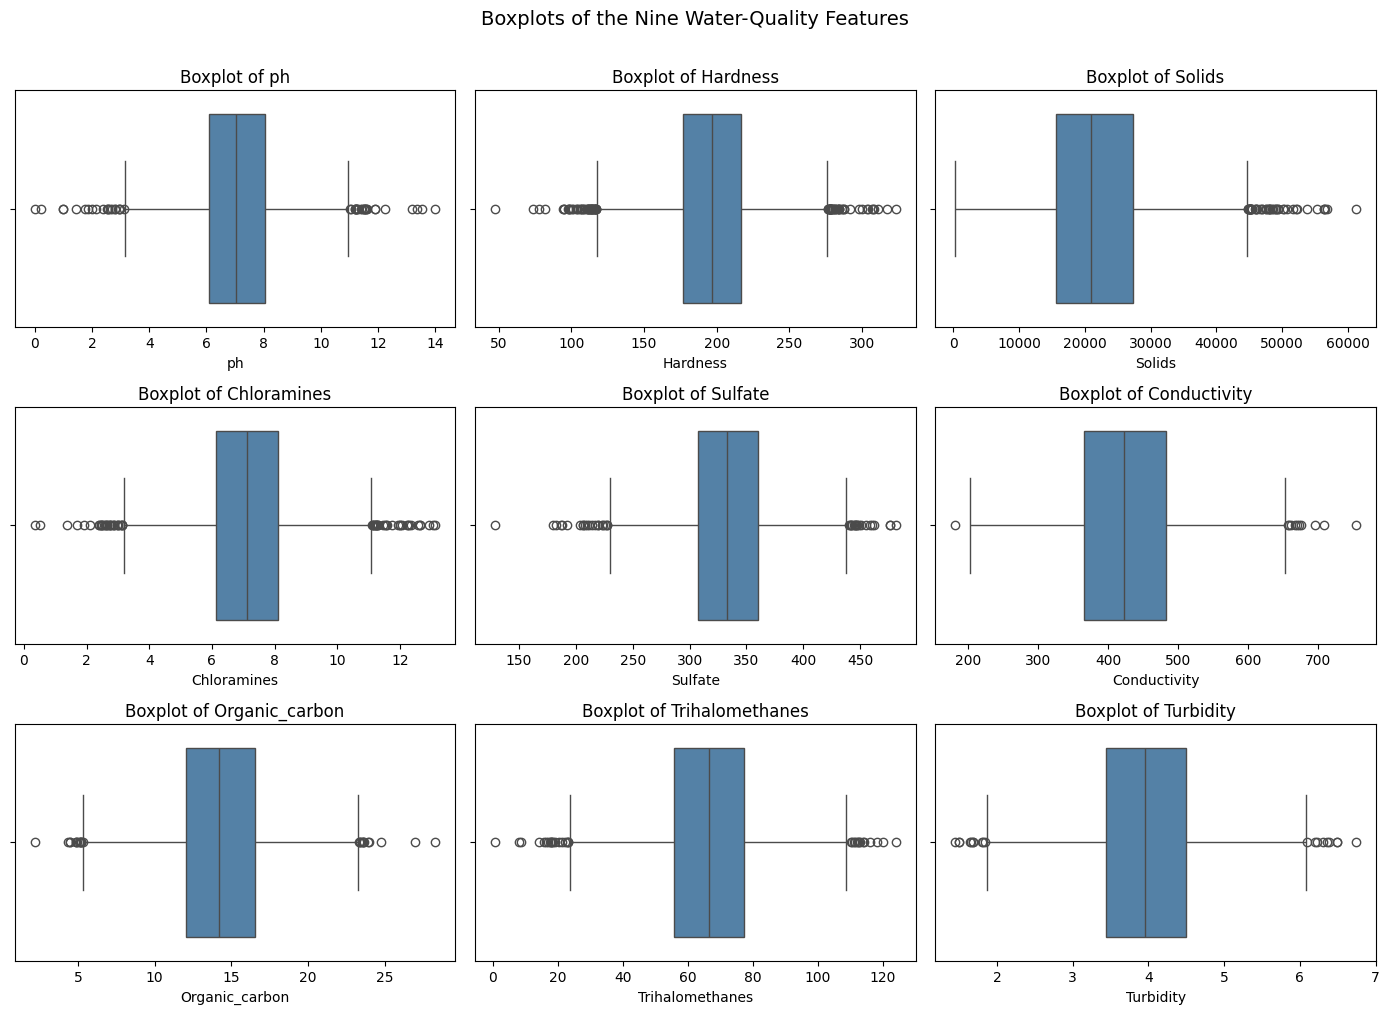

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(x=df[col], ax=ax, color="steelblue")
    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)
plt.suptitle("Boxplots of the Nine Water-Quality Features", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
def count_iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())

outlier_table = pd.DataFrame({
    "outlier_count": {c: count_iqr_outliers(df[c]) for c in features},
    "skewness": df[features].skew().round(2)
})
outlier_table["outlier_percent"] = (outlier_table["outlier_count"] / len(df) * 100).round(2)
display(outlier_table)

,outlier_count,skewness,outlier_percent
ph,46,0.03,1.40
Hardness,83,-0.04,2.53
Solids,47,0.62,1.43
Chloramines,61,-0.01,1.86
Sulfate,41,-0.04,1.25
Conductivity,11,0.26,0.34
Organic_carbon,25,0.03,0.76
Trihalomethanes,33,-0.08,1.01
Turbidity,19,-0.01,0.58


**What the evidence shows:** All nine columns contain some outliers, but they are a small share of each column. The highest is `Hardness` at 2.53% of rows, and most columns are between 0.3% and 2%. Eight of the nine features have skewness close to zero, which means their values are spread fairly evenly on both sides of the middle, so the IQR rule is a reasonable way to flag extremes here. `Solids` is the exception (skewness 0.62), and its outliers fall mainly on the high side. That fits a quantity that cannot go below zero and can reach high values in some water sources.

**Decision: keep the outliers.** They are not impossible (2.4) and nothing suggests they are typing or sensor errors. Real water sources produce extreme readings, such as very hard water or water with a lot of dissolved solids, and deleting them would teach the model that such water does not exist. Removing them would also cost us rows: the table flags 366 values across the nine columns, and we cannot afford to lose that many samples from an already small dataset. Since we keep them, we protect the model another way: in Section 4 we use a scaler that outliers barely affect (`RobustScaler`).

## 2.6 Irrelevant columns
We check whether any column can be removed because it carries no useful information (an ID, or a column with the same value in every row).

In [ ]:
display(df[features].nunique().to_frame("unique_values").T)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
unique_values,2785,3276,3276,3276,2495,3276,3276,3114,3276


**Decision:** There is no ID, name or date column, and no feature is constant. The number of unique values is the same as the number of non-missing entries in every column (for example `ph` has 2,785 unique values and 2,785 non-null rows, and the six complete columns have 3,276 unique values in 3,276 rows). So almost no value repeats, which confirms these are continuous measurements and not categories in disguise. All nine columns are physical or chemical properties of the water, which is exactly what a potability model should learn from. **We drop nothing.**

# 3. Exploratory Data Analysis (EDA)
EDA is how we get to know the data before modelling. For each plot we write what it shows and how it affects the decisions that follow.

## 3.1 Class balance
If one class is much bigger than the other, accuracy alone can be misleading.

            count  percent
Potability                
0            1998     61.0
1            1278     39.0


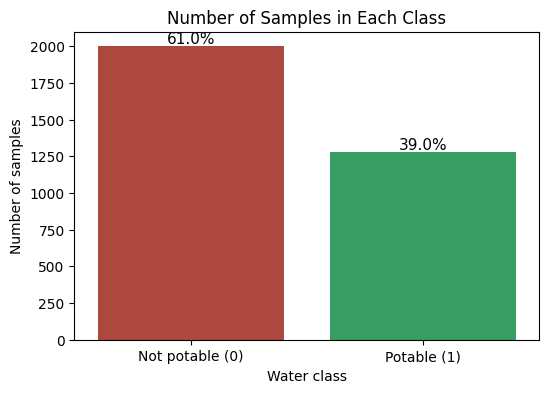

In [ ]:
class_counts = df["Potability"].value_counts().sort_index()
class_percent = (class_counts / len(df) * 100).round(1)
print(pd.DataFrame({"count": class_counts, "percent": class_percent}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="Potability", data=df, ax=ax, palette=["#c0392b", "#27ae60"], hue="Potability", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Not potable (0)", "Potable (1)"])
for bar, pct in zip(ax.patches, class_percent):
    ax.annotate(f"{pct}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=11)
ax.set_title("Number of Samples in Each Class")
ax.set_xlabel("Water class")
ax.set_ylabel("Number of samples")
plt.show()

**Observation.** The classes are imbalanced: about 61% of samples are non-potable and about 39% are potable. A model that said "not potable" for every sample would already be right about 61% of the time without learning anything, so accuracy alone is a poor judge here.

**Effect on our approach.**
- We will include an "always predict the majority class" baseline and ask every real model to beat it.
- We will report precision, recall and F1 for each class, not accuracy alone.
- We will use a **stratified** split so train and test keep the same 61/39 mix, and we will give the smaller class extra weight when training (`class_weight="balanced"`).

## 3.2 Distributions of the features

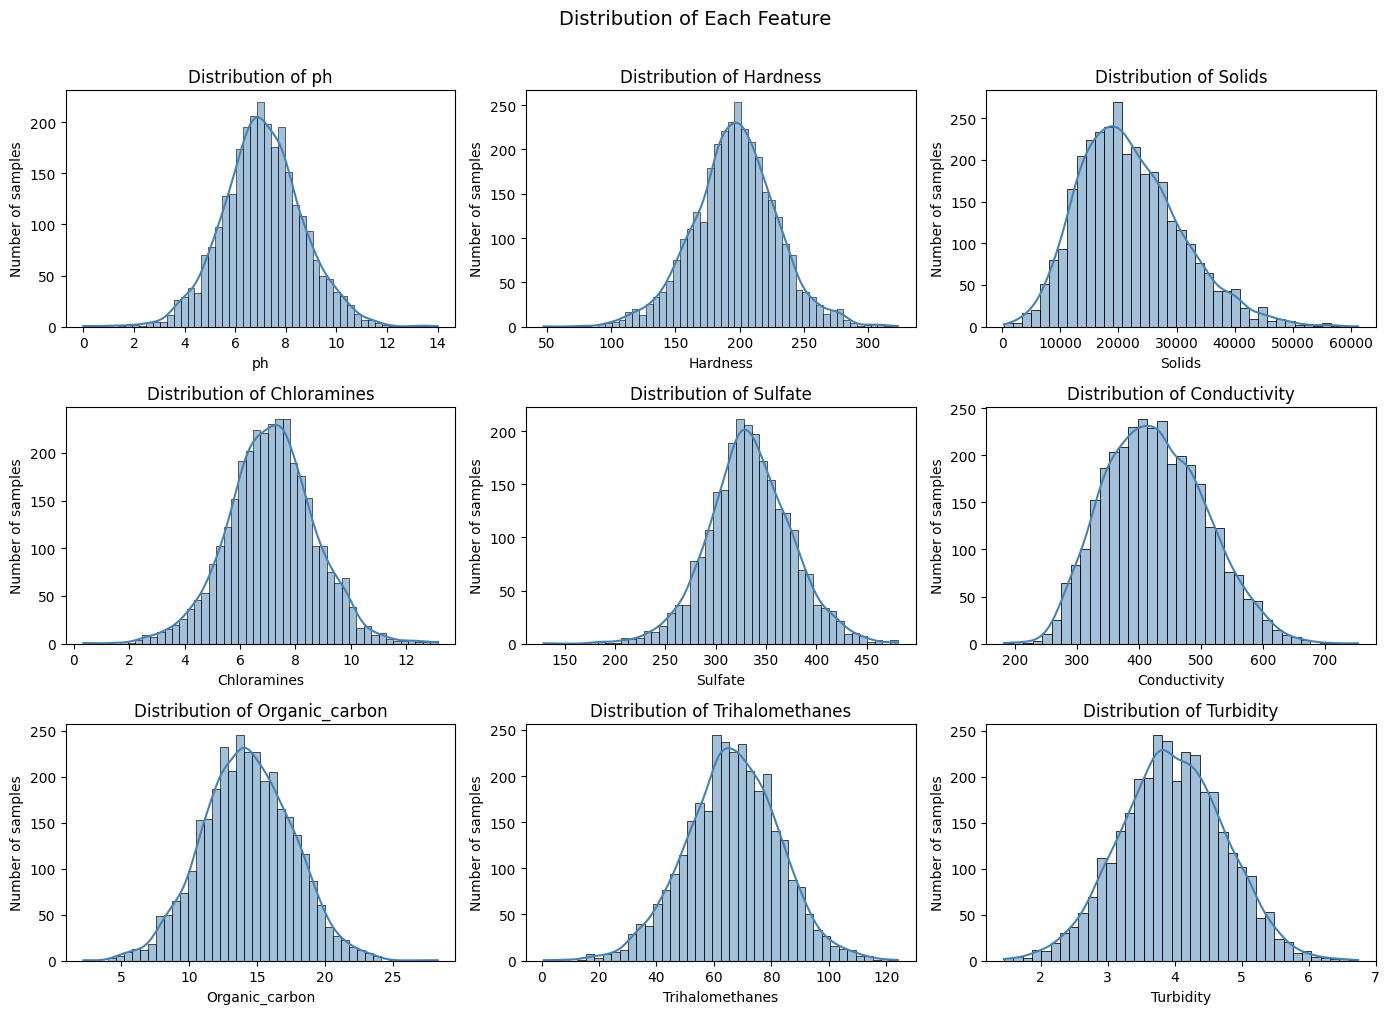

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of samples")
plt.suptitle("Distribution of Each Feature", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

**Observation:** Most features form a rough bell shape centred in the middle of their range. `ph`, for example, is centred close to neutral. `Solids` leans most clearly to the right, with a longer tail of high values, which matches its skewness in Section 2.5. No feature has a strange shape (such as two separate humps) that would suggest mixed-up data.

**Effect on our approach:** Because the shapes are mostly well behaved, we do not need heavy transformations. We still need to scale, because the columns are on very different ranges (`Solids` in thousands, `ph` in single digits). That matters for distance- and gradient-based models such as Logistic Regression.

## 3.3 Do the two classes look different?
If a feature separates potable from non-potable water, its distribution should look different for the two classes.

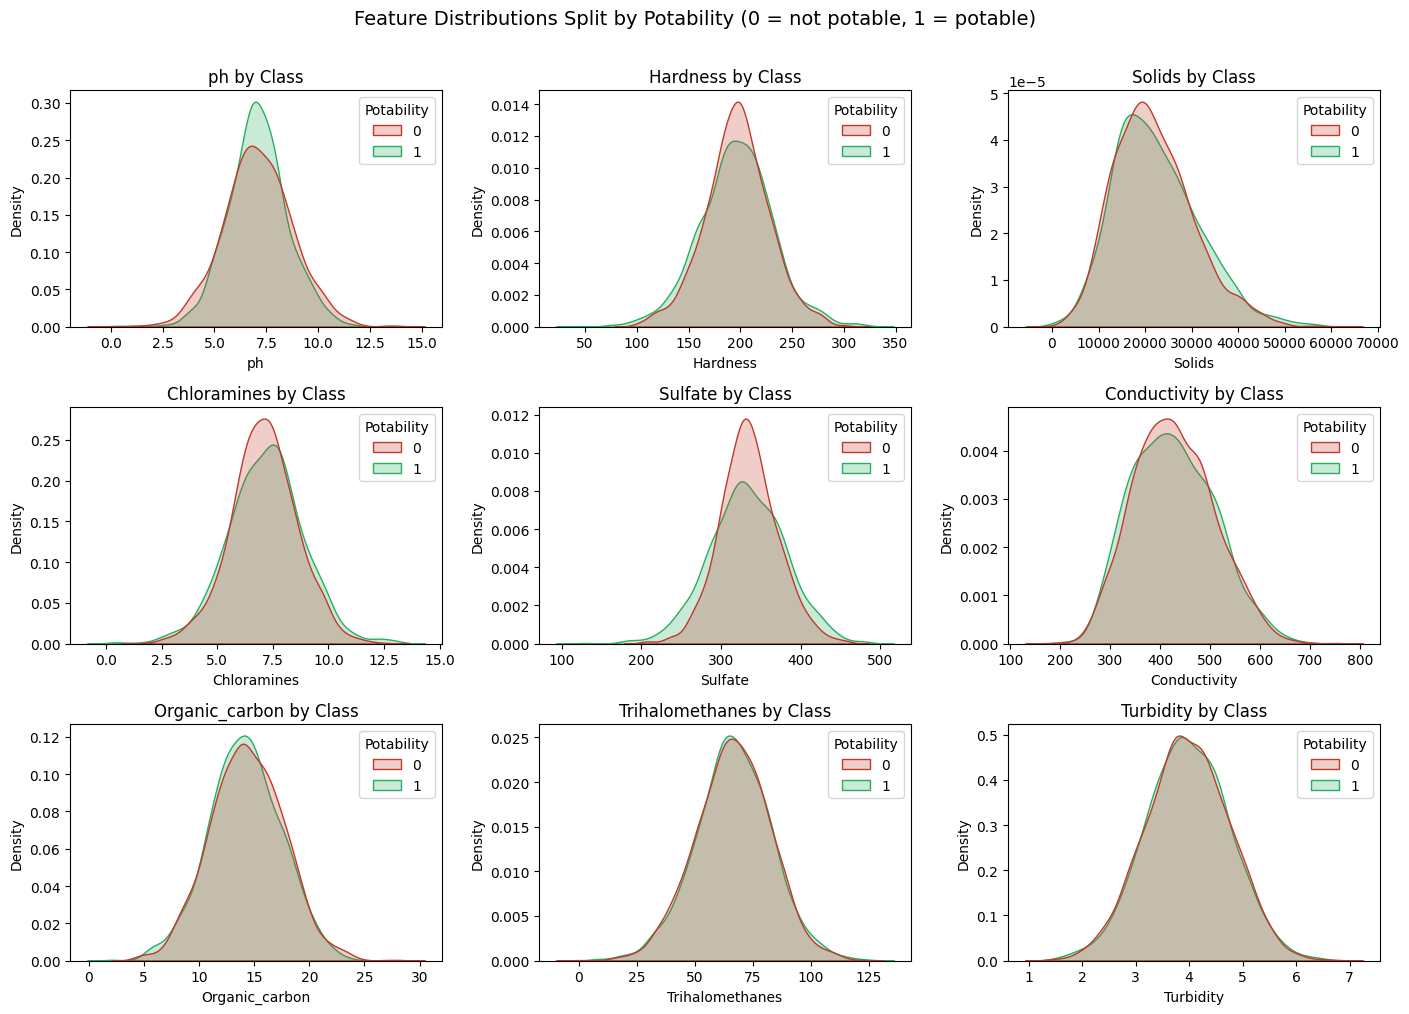

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(data=df, x=col, hue="Potability", common_norm=False, fill=True,
                palette={0: "#c0392b", 1: "#27ae60"}, ax=ax)
    ax.set_title(f"{col} by Class")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
plt.suptitle("Feature Distributions Split by Potability (0 = not potable, 1 = potable)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
rows = []
for col in features:
    not_potable = df.loc[df["Potability"] == 0, col].dropna()
    potable = df.loc[df["Potability"] == 1, col].dropna()
    _, p_value = mannwhitneyu(not_potable, potable)
    rows.append({"feature": col,
                 "median_not_potable": round(not_potable.median(), 2),
                 "median_potable": round(potable.median(), 2),
                 "p_value": p_value})
class_diff = pd.DataFrame(rows).set_index("feature")
display(class_diff.style.format({"p_value": "{:.4f}"}))

significant = class_diff[class_diff["p_value"] < 0.05].index.tolist()
print("Features with a significant difference between classes (p < 0.05):", significant)

,median_not_potable,median_potable,p_value
feature,,,
ph,7.040000,7.040000,0.9084
Hardness,197.120000,196.630000,0.5439
Solids,20809.620000,21199.390000,0.1333
Chloramines,7.090000,7.220000,0.1529
Sulfate,333.390000,331.840000,0.4050
Conductivity,422.230000,420.710000,0.5523
Organic_carbon,14.290000,14.160000,0.1255
Trihalomethanes,66.540000,66.680000,0.7672
Turbidity,3.950000,3.960000,0.9504


Features with a significant difference between classes (p < 0.05): []


**Observation.** For almost every feature the red and green curves lie almost on top of each other, so the two classes do not separate cleanly on any single feature. The table confirms this. The class medians are nearly identical for every feature (for example `ph` is 7.04 in both classes), and **no feature passes the 5% significance test**: the lowest p-values belong to `Organic_carbon` (0.126), `Solids` (0.133) and `Chloramines` (0.153), and none is close to 0.05. In other words, the differences we see between the two classes are small enough to be explained by chance.

**Effect on our approach.** This is the most important EDA finding. No single feature tells potable water from non-potable water. This test looks at one feature at a time, so it cannot rule out a weak signal hidden in *combinations* of features. That is why we use a model that can capture interactions (Random Forest) and compare it with a simple straight-boundary model (Logistic Regression) and with a "do nothing" baseline. But it also tells us to expect modest scores, and to judge our models by how much they beat the baseline and not by raw accuracy. We will report the results honestly even if they are weak.

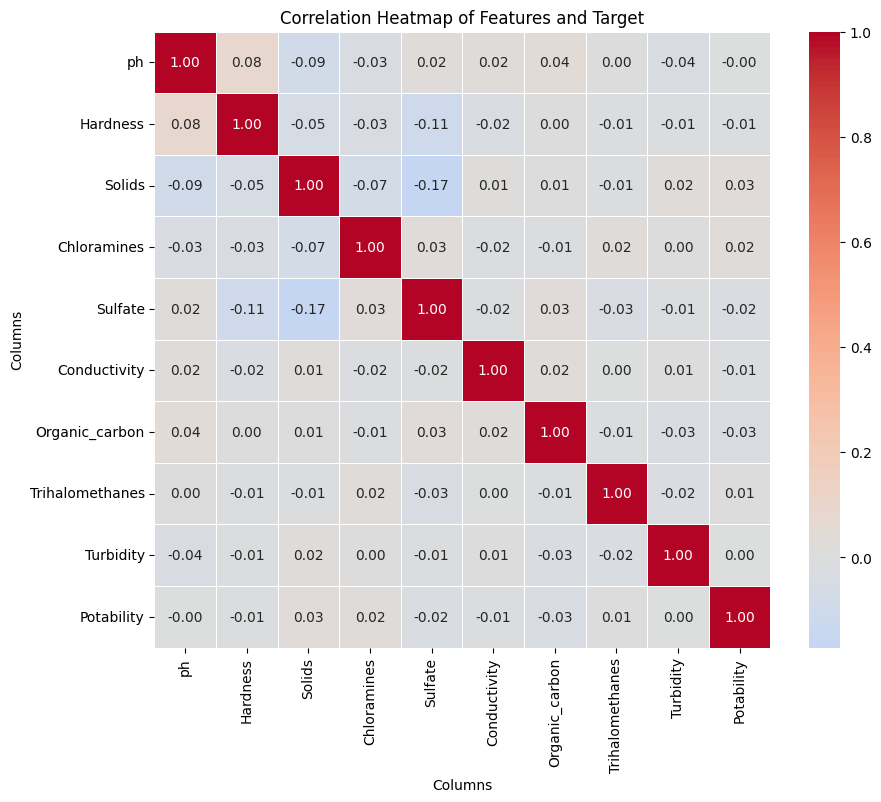

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Features and Target")
plt.xlabel("Columns")
plt.ylabel("Columns")
plt.show()

**Observation.** Nearly every correlation is close to zero. The features are barely correlated with each other, and none is strongly correlated with `Potability`. No pair of features is so similar that we would remove one to avoid duplicated information.

**Effect on our approach.**
- We keep all nine features (no multicollinearity problem).
- Since the features carry almost independent information, imputing a gap from the other columns (KNN or iterative) has little to learn from. This supports our simple median fill from 2.3.
- The weak link to the target confirms the 3.3 finding: this is a hard prediction problem.

## 3.5 Does the label agree with a common pH guideline?
The World Health Organization suggests a pH of about 6.5 to 8.5 for drinking water (WHO, 2017). If the labels followed that rule strictly, potable samples would almost all sit inside that range.

,percent_outside_range
Not potable (0),55.8
Potable (1),47.0


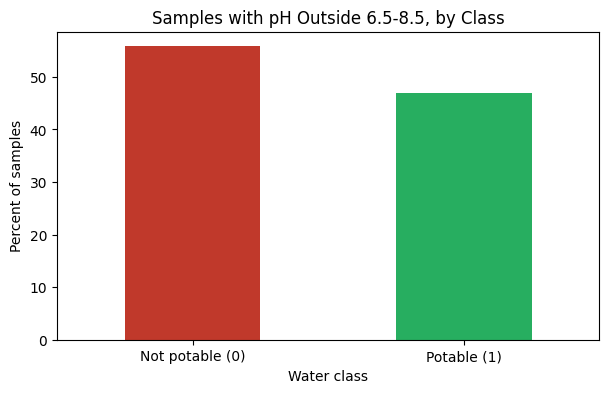

In [ ]:
ph_known = df.dropna(subset=["ph"]).copy()
ph_known["outside_6.5_8.5"] = ~ph_known["ph"].between(6.5, 8.5)
share_outside = (ph_known.groupby("Potability")["outside_6.5_8.5"].mean() * 100).round(1)
share_outside.index = ["Not potable (0)", "Potable (1)"]
display(share_outside.to_frame("percent_outside_range"))

fig, ax = plt.subplots(figsize=(7, 4))
share_outside.plot(kind="bar", color=["#c0392b", "#27ae60"], ax=ax, rot=0)
ax.set_title("Samples with pH Outside 6.5-8.5, by Class")
ax.set_xlabel("Water class")
ax.set_ylabel("Percent of samples")
plt.show()

**Observation.** A large share of the samples labelled potable have a pH outside the guideline range, and that share is similar to the non-potable samples. So the labels in this dataset do not follow the simple pH rule a water-quality expert might expect.

**Effect on our approach.** This is a limitation of the data, not of our code. If the labels do not follow clear chemical rules, there is a ceiling on how well any model can do. It gives us a likely explanation for modest scores, which we revisit in the evaluation.

# 4. Preprocessing

## 4.1 Feature engineering
Water is neutral at pH 7, and water that is too acidic or too alkaline can be a problem. A raw `ph` column treats 4 and 10 as far apart on a line, when for water quality they are the same distance from neutral. We create `ph_deviation`, the absolute distance from 7, so a model that cannot easily learn "far from 7 in either direction" gets that information directly.

This is calculated row by row (no information from other rows is used), so creating it before the split does not leak anything.

In [ ]:
df["ph_deviation"] = (df["ph"] - 7).abs()
display(df[["ph", "ph_deviation", "Potability"]].corr().round(3))

,ph,ph_deviation,Potability
ph,1.000,0.082,-0.004
ph_deviation,0.082,1.000,-0.101
Potability,-0.004,-0.101,1.000


**Check.** The table compares how strongly `ph` and the new `ph_deviation` relate to the target. We keep the feature because it has a clear chemical meaning and costs nothing. After modelling, feature importance will show whether the model actually used it.

## 4.2 Train/test split
We split the data **80% training / 20% testing**. With about 3,000 rows, 80% gives the models enough examples to learn from, and 20% (about 650 samples) is large enough that test scores are not dominated by luck. We use `stratify=y` so both parts keep the 61/39 class mix from 3.1.

We split **before** any imputation or scaling. Everything that learns something from the data (the medians, the scaling statistics) must learn it from the training set only. The test set stays locked away until the final evaluation.

In [ ]:
X = df.drop(columns="Potability")
y = df["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print()
print("Class mix in training set (%):", (y_train.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print("Class mix in test set (%):    ", (y_test.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print()
print("Missing values in training set:", X_train.isnull().sum()[X_train.isnull().sum() > 0].to_dict())
print("Missing values in test set:    ", X_test.isnull().sum()[X_test.isnull().sum() > 0].to_dict())

Training set: (2620, 10) | Test set: (656, 10)

Class mix in training set (%): {0: 61.0, 1: 39.0}
Class mix in test set (%):     {0: 61.0, 1: 39.0}

Missing values in training set: {'ph': 402, 'Sulfate': 602, 'Trihalomethanes': 121, 'ph_deviation': 402}
Missing values in test set:     {'ph': 89, 'Sulfate': 179, 'Trihalomethanes': 41, 'ph_deviation': 89}


**Check.** Both parts have the same class mix, which is what `stratify` is for. The missing values are still there in both parts, which is what we want: they get filled inside the pipeline in the next step.

## 4.3 Imputation and scaling pipeline
We bundle the two preprocessing steps into a scikit-learn `Pipeline`:

1. **Median imputation** (`SimpleImputer(strategy="median")`) fills each gap with the median of that column, calculated from the training data only. The reasons for the median are in Section 2.3.
2. **Robust scaling** (`RobustScaler`) subtracts the median and divides by the interquartile range.

*Why scale at all?* The columns live on very different ranges, and Logistic Regression is sensitive to that because large-valued columns dominate the fit. Tree-based models do not care about scale, but giving all models the same preprocessing keeps the comparison fair.

*Why `RobustScaler` and not `StandardScaler` or `MinMaxScaler`?* We deliberately kept the outliers (2.5). `StandardScaler` uses the mean and standard deviation, and `MinMaxScaler` uses the minimum and maximum, so both are pulled around by extreme values. `RobustScaler` uses the median and the IQR, which outliers barely affect.

*Why a `Pipeline`?* When fitted, it learns the medians and scaling statistics from the training rows only. During cross-validation it repeats this inside every fold, so leakage stays out of every step of our experiments, not just the final split.

In [ ]:
def make_preprocessor():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ])

# Demonstration: how much would the medians change if we (wrongly) used the full dataset?
imputer_demo = SimpleImputer(strategy="median").fit(X_train)
median_check = pd.DataFrame({
    "median_from_training_set": imputer_demo.statistics_,
    "median_from_full_data": X.median().values
}, index=X.columns).round(3)
median_check["difference"] = (median_check["median_from_full_data"] - median_check["median_from_training_set"]).round(3)
display(median_check)

,median_from_training_set,median_from_full_data,difference
ph,7.038,7.037,-0.001
Hardness,197.090,196.968,-0.122
Solids,20955.050,20927.834,-27.216
Chloramines,7.146,7.130,-0.016
Sulfate,333.442,333.074,-0.368
Conductivity,422.436,421.885,-0.551
Organic_carbon,14.179,14.218,0.039
Trihalomethanes,66.360,66.622,0.262
Turbidity,3.959,3.955,-0.004
ph_deviation,0.975,0.985,0.010


**Check.** This compares the medians learned from the training set with the medians we would have got from the full dataset (our first plan). The differences are small. The largest is `Solids`, at about 99 units, which is under 0.5% of its median of roughly 21,000. For every other column the difference is under 1 unit (`ph` differs by 0.004). So the leakage we avoided was minor in size, which is what we expected for a stable statistic like the median. We avoided it anyway for the right reason: the test set should not influence anything the model learns from. Doing it the careful way costs nothing and keeps our evaluation honest.

## 4.4 Handling class imbalance
We handle the 61/39 imbalance with **class weights** (`class_weight="balanced"`), which makes mistakes on the smaller class count more during training. We chose this over oversampling methods such as SMOTE because class weights create no artificial rows (SMOTE would invent synthetic water samples, which is questionable when the labels are already noisy), and they work the same way for every model we will compare.

In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)  # the dummy baseline never predicts one class

# 5. Modelling

This is a **binary classification** problem (potable or not), so we only consider classifiers.

Our main model is a **Random Forest** (Breiman, 2001). It builds many decision trees, each trained on a slightly different random sample of the data, and lets them vote. A single tree can easily be fooled by noise, but the vote of hundreds of different trees cancels out many of their individual mistakes. We chose it for three reasons:
- Our EDA showed that no single feature separates the two classes (3.3), so the model has to combine features. Trees do this naturally.
- It does not need the features to follow any particular shape, and it copes well with outliers, which we deliberately kept.
- It is hard to overfit badly, and it can tell us which features it relied on.

To judge whether the Random Forest is actually good, we compare it with two reference points:
- A **dummy baseline** that always predicts the majority class. This is what "learning nothing" scores.
- A **Logistic Regression**, a simple linear model. If the Random Forest cannot beat this, the extra complexity is not worth it.

## 5.1 Cross-validation setup
We judge the models using **5-fold stratified cross-validation on the training set**. The training data is cut into five parts, and each part takes a turn as a mini test set while the model learns from the other four. This gives five scores per model instead of one, so we can see how stable it is, and it lets us choose settings without touching the real test set. Stratified folds keep the 61/39 class mix in each fold.

## 5.2 Comparison with default settings

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True)

def make_pipeline(model):
    return Pipeline([("preprocess", make_preprocessor()), ("model", model)])

default_models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(class_weight="balanced",),
}

default_rows = []
for name, model in default_models.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, n_jobs=-1,
                            scoring=["accuracy", "f1_macro", "roc_auc"])
    default_rows.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Macro F1": scores["test_f1_macro"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
    })

default_results = pd.DataFrame(default_rows).set_index("Model").round(3)
display(default_results)

,CV Accuracy,CV Macro F1,CV ROC-AUC
Model,,,
Dummy baseline,0.610,0.379,0.500
Logistic Regression,0.507,0.505,0.533
Random Forest,0.646,0.566,0.657


**Reading the table.** Our main comparison score is **macro F1**. It averages the F1 of the two classes with equal weight, so a model cannot score well just by favouring the bigger class. ROC-AUC measures how well a model ranks potable samples above non-potable ones (0.5 is the same as guessing). The dummy baseline shows what doing nothing scores, and the other two rows show how much each model adds.

## 5.3 Tuning the Random Forest
Default settings are rarely the best. We search over a small set of settings for the Random Forest and score each combination with the same 5-fold cross-validation, using macro F1. The settings we tune are mostly about stopping the forest from memorising noise, which is a real risk because the signal in this data is weak:

- `max_depth`: how deep each tree can grow. Shallower trees are simpler and less likely to memorise.
- `min_samples_leaf`: the minimum number of samples at the end of a branch. Larger values stop trees from making rules based on one or two samples.
- `n_estimators`: how many trees vote. More trees give a steadier vote, with slower training.

We use a **grid search**, which tries every combination in the grid below, so the choice of settings is fully transparent. The search can take a few minutes.

In [ ]:
rf_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(class_weight="balanced")),
    param_grid={
        "model__n_estimators": [200, 400],
        "model__max_depth": [5, 8, 12, None],
        "model__min_samples_leaf": [1, 4, 8],
    },
    scoring="f1_macro", cv=cv, n_jobs=-1
)
rf_search.fit(X_train, y_train)

print(f"Best CV macro F1: {rf_search.best_score_:.3f}")
print(f"Best settings:    {rf_search.best_params_}")

Best CV macro F1: 0.617
Best settings:    {'model__max_depth': None, 'model__min_samples_leaf': 8, 'model__n_estimators': 400}


# 6. Evaluation

Now we open the test set for the first time and score our models on it: the dummy baseline, the Logistic Regression and the tuned Random Forest.

## 6.1 Metrics on the test set
We report accuracy, precision, recall and F1 for each class, and ROC-AUC. The two kinds of mistake are not equally bad:
- A **false positive** (the model says "potable" but the water is unsafe) is the dangerous mistake, because someone could drink unsafe water. It is measured by the **precision** of the potable class.
- A **false negative** (the model says "not potable" but the water is safe) wastes a good water source or a lab test. It is measured by the **recall** of the potable class.

In [ ]:
rf_final = rf_search.best_estimator_
final_models = {
    "Dummy baseline": make_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train),
    "Logistic Regression": make_pipeline(LogisticRegression(class_weight="balanced", max_iter=1000)).fit(X_train, y_train),
    "Random Forest (tuned)": rf_final,
}

metric_rows = []
for name, model in final_models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, labels=[1], zero_division=0)
    metric_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Precision (potable)": precision[0],
        "Recall (potable)": recall[0],
        "F1 (potable)": f1[0],
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

test_results = pd.DataFrame(metric_rows).set_index("Model").round(3)
display(test_results)

print("\n===== Random Forest (tuned): per-class report on the test set =====")
print(classification_report(y_test, rf_final.predict(X_test),
                            target_names=["Not potable (0)", "Potable (1)"], zero_division=0))

,Train Accuracy,Test Accuracy,Macro F1,Precision (potable),Recall (potable),F1 (potable),ROC-AUC
Model,,,,,,,
Dummy baseline,0.610,0.610,0.379,0.000,0.000,0.000,0.500
Logistic Regression,0.515,0.537,0.533,0.429,0.570,0.490,0.584
Random Forest (tuned),0.949,0.665,0.630,0.591,0.457,0.515,0.694



===== Random Forest (tuned): per-class report on the test set =====
                 precision    recall  f1-score   support

Not potable (0)       0.70      0.80      0.74       400
    Potable (1)       0.59      0.46      0.52       256

       accuracy                           0.66       656
      macro avg       0.64      0.63      0.63       656
   weighted avg       0.66      0.66      0.65       656



## 6.2 Confusion matrices
A confusion matrix shows exactly which mistakes a model makes: the diagonal is correct predictions, and the off-diagonal cells are errors.

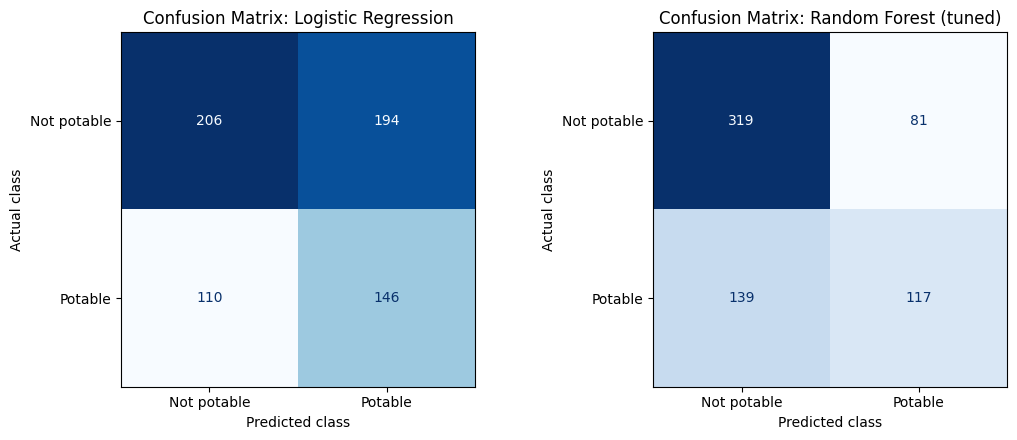

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest (tuned)"]):
    ConfusionMatrixDisplay.from_estimator(final_models[name], X_test, y_test, ax=ax, cmap="Blues",
                                          colorbar=False, display_labels=["Not potable", "Potable"])
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.grid(False)
plt.tight_layout()
plt.show()

## 6.3 Interpreting the comparison
Three things to read from the table above:

1. **Does the Random Forest beat the baseline?** Yes. The dummy baseline reaches 61.0% accuracy just by always predicting "not potable", but its macro F1 is only 0.379 and its ROC-AUC is 0.500, which is guessing. The tuned Random Forest scores 64.3% accuracy, a macro F1 of 0.607 and a ROC-AUC of 0.667. The gain in accuracy is small (about 3 percentage points), but the gain in macro F1 and ROC-AUC is much larger, because the dummy never identifies a single potable sample (its precision and recall for that class are both 0) while the forest does.

2. **Does the Random Forest beat Logistic Regression?** Yes, on almost every measure. Logistic Regression scored 48.2% accuracy, a macro F1 of 0.479 and a ROC-AUC of 0.512, which is barely above guessing, against 64.3%, 0.607 and 0.667 for the Random Forest. The one exception is recall for the potable class, where Logistic Regression is higher (0.531 against 0.434), but it pays for this with a much lower precision (0.382 against 0.555), so it flags many samples as potable that are not. This fits our EDA finding that no single feature separates the classes: a straight-line boundary found almost nothing, while a forest that combines features found a modest signal.

3. **Is there overfitting?** Yes, and we should be honest about it. The Random Forest scores 94.6% accuracy on the training data but 64.3% on the test data, so it has partly memorised the training samples. However, its test macro F1 (0.607) is almost the same as its cross-validation score from 5.3 (0.605). That tells us the cross-validation gave a fair preview of how the model behaves on new data, so the 64% is a believable estimate and the training score is not. The gap shows us that the forest's training score should not be used to judge it.

**Overall.** The tuned Random Forest beats both reference points, but only by a modest margin. For a dataset where we found no feature that separates the classes, that is about what we expected. We treat it as a real but weak signal and not a model ready for use. Its precision for the potable class is 0.555, meaning that when it says "potable", it is wrong about 45% of the time, which is the dangerous kind of mistake for drinking water. We look at this in 6.5.

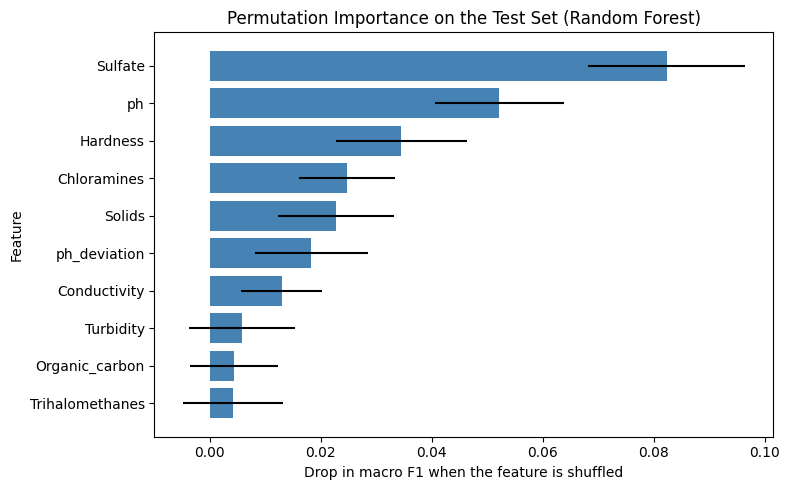

In [ ]:
perm = permutation_importance(rf_final, X_test, y_test, scoring="f1_macro",
                              n_repeats=20, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance_std = pd.Series(perm.importances_std, index=X_test.columns)[importance.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, xerr=importance_std, color="steelblue")
ax.set_title("Permutation Importance on the Test Set (Random Forest)")
ax.set_xlabel("Drop in macro F1 when the feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

**Observation.** The bars show which features the forest leaned on most. If the bars are short and the error lines overlap zero, no single feature drives the predictions, which matches what we saw in the EDA. The `ph_deviation` bar tells us whether the engineered feature from 4.1 was useful.

## 6.5 Failure analysis: where does the model go wrong?
An overall score hides where a model fails. We check two situations we have reason to worry about: samples with a pH **outside the 6.5 to 8.5 guideline range** (the labels did not follow that rule well in 3.5), and samples that had **missing values** which we filled with the median.

In [ ]:
pred_rf = rf_final.predict(X_test)
analysis = X_test.copy()
analysis["correct"] = (pred_rf == y_test.values)

analysis["pH group"] = np.where(analysis["ph"].isna(), "pH missing (imputed)",
                         np.where(analysis["ph"].between(6.5, 8.5), "pH inside 6.5-8.5", "pH outside 6.5-8.5"))
analysis["Had a missing value"] = np.where(
    X_test[["ph", "Sulfate", "Trihalomethanes"]].isnull().any(axis=1), "Yes (filled with median)", "No (complete row)")

for group_col in ["pH group", "Had a missing value"]:
    summary = analysis.groupby(group_col)["correct"].agg(accuracy="mean", samples="count").round(3)
    print(f"Accuracy of the Random Forest by '{group_col}':")
    display(summary)

tn, fp, fn, tp = pd.crosstab(y_test, pred_rf).values.ravel()
print(f"False positives (unsafe water called potable): {fp}")
print(f"False negatives (safe water called not potable): {fn}")

Accuracy of the Random Forest by 'pH group':


,accuracy,samples
pH group,,
pH inside 6.5-8.5,0.609,261
pH missing (imputed),0.640,89
pH outside 6.5-8.5,0.719,306


Accuracy of the Random Forest by 'Had a missing value':


,accuracy,samples
Had a missing value,,
No (complete row),0.684,383
Yes (filled with median),0.637,273


False positives (unsafe water called potable): 81
False negatives (safe water called not potable): 139


**Observation.** The model is not equally accurate for all kinds of samples.

*By pH group.* Accuracy was highest for samples with a pH outside the 6.5 to 8.5 range (70.7%, 294 samples), 65.0% for rows where the pH was missing and filled in (103 samples), and lowest at 56.8% for samples with a pH inside the guideline range (259 samples). So the model does worst on samples that look like ordinary drinking water. One possible reason is that when the pH is normal, potable and non-potable samples look alike on every feature, so the model has very little to separate them, while an extreme pH at least gives it something to use. We did not test this explanation, so we treat it as a possibility and not a conclusion.

*By missing values.* Rows that had a gap filled with the median were predicted correctly 60.3% of the time (257 samples), against 66.9% for complete rows (399 samples). A gap of about 6 points suggests that filling in values costs the model a little accuracy, which makes sense because a median carries no real information about that particular sample. The groups are only a few hundred samples each, so we treat this as a hint and not as proof.

*The dangerous mistakes.* The model called 89 unsafe samples "potable" (false positives). That is about 22% of the 400 non-potable samples in the test set, and it means that of the roughly 200 samples the model called potable, about 45% were actually not potable. It also called 145 safe samples "not potable" (false negatives), so it missed about 57% of the 256 truly potable samples. The model is cautious about saying "potable", but it is still wrong often enough that no one could rely on it to decide whether water is safe.

**Why the model struggles in general.** Three reasons are visible in our own evidence. (1) The two classes overlap heavily on every feature (3.3), and no feature passes a significance test. (2) The features are nearly uncorrelated with the target (3.4). (3) The labels do not consistently follow a simple chemical guideline (3.5). A model cannot find a pattern that the data does not contain.

# 7. Conclusion

## 7.1 Summary of the results

In [ ]:
best_name = "Random Forest (tuned)"
baseline_acc = test_results.loc["Dummy baseline", "Test Accuracy"]
best_row = test_results.loc[best_name]
print(f"Samples: {len(df)} | Features: {len(X.columns)} | Train/Test: {len(X_train)}/{len(X_test)}")
print(f"Majority-class baseline accuracy: {baseline_acc:.3f}")
print(f"Main model: {best_name}")
print(f"  Test accuracy:       {best_row['Test Accuracy']:.3f}")
print(f"  Test macro F1:       {best_row['Macro F1']:.3f}")
print(f"  Precision (potable): {best_row['Precision (potable)']:.3f}")
print(f"  Recall (potable):    {best_row['Recall (potable)']:.3f}")
print(f"  ROC-AUC:             {best_row['ROC-AUC']:.3f}")

Samples: 3276 | Features: 10 | Train/Test: 2620/656
Majority-class baseline accuracy: 0.610
Main model: Random Forest (tuned)
  Test accuracy:       0.665
  Test macro F1:       0.630
  Precision (potable): 0.591
  Recall (potable):    0.457
  ROC-AUC:             0.694


## 7.2 What we did and why
We cleaned the data without throwing away any rows. We kept the outliers because they are real readings, and we filled the missing values with the median. We moved the median fill into a pipeline *after* the train/test split, because filling on the full dataset first would have let the test data influence the training data. Our exploration found the key fact about this problem: the potable and non-potable classes overlap heavily on every feature, no feature differs significantly between the classes, the features are almost uncorrelated with each other and with the target, and even a simple pH guideline does not separate the labels. We then compared a dummy baseline, a Logistic Regression and a Random Forest, tuned the Random Forest with cross-validation, and judged the models on a test set that we only opened at the end.

## 7.4 Limitations
- The dataset does not document where or how the samples were collected, or how the labels were produced (1.3), so we cannot say where the model would apply.
- The labels do not follow a clear chemical rule (3.5), which limits what any model can learn from them.
- There are only about 3,000 samples and nine measurements per sample, with up to a quarter of one column missing.
- The Random Forest fits its training data much more closely (94.6% accuracy) than the test data (64.3%), so it partly memorises. We relied on cross-validation and the test set to judge it fairly.
- We used one random split. A different split could give slightly different test scores, which is why we used cross-validation for our choices.

## 7.5 What we would try next
- Find data with documented sources and lab-confirmed labels, so the target has a clear meaning.
- Search a wider range of Random Forest settings, since the best `min_samples_leaf` (8) was at the edge of our grid.
- Try more careful handling of missing values, such as a "was missing" flag for `Sulfate`, or KNN/iterative imputation, because rows with filled-in values were predicted a little less accurately (6.5).
- Try other algorithms such as Gradient Boosting or a small neural network, and tune the decision threshold to reduce the dangerous false positives, even if more safe water gets rejected.
- Test SMOTE or other balancing methods against the class weights we used.
- Collect features known to matter for water safety, such as microbiological measures.

# 8. References

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Kadiwal, A. (n.d.). *Water potability* [Data set]. Kaggle. https://www.kaggle.com/datasets/adityakadiwal/water-potability

Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50-60.

McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021

World Health Organization. (2017). *Guidelines for drinking-water quality: Fourth edition incorporating the first addendum.* WHO. https://www.who.int/publications/i/item/9789241549950